# **Langchain Tutorial for intermediate agentic ai learner.**
> 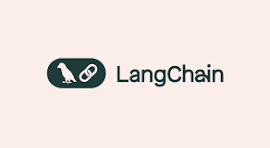 <br>
> ### **We use the class python based for developing ai agent, tools we used are the followings :-**
> - Langchain
> - Langgraph
> - Python
> - Tavily

## **01. We call dependence libraries here .** 

In [1]:
from langchain_openai import ChatOpenAI
from langchain_tavily import TavilySearch
from langchain.agents import create_agent
from langchain.tools import tool
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

In [2]:
""" We load our data from env by call load_dotenv method """
load_dotenv()

True

## **02. We define our tool here.**

In [3]:
""" we call tavily search method here """
tavily_search = TavilySearch(
    max_results=5,
    topic="general"
)

@tool("web_search")
def web_search(query:str)->str:
    """ We search results from web search tool using tavily."""
    search_results = tavily_search.invoke({"query":query})
    return str(search_results)
    

## **03. We initialize the LLM here.**

In [4]:
""" we initilize the llm using openai model. """
llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0.5
)

## **04. We generate our prompt here.**

In [5]:
""" we create prompt to make our agent to understand """

prompt =  """
            You are a helpful Web Search AI Assistant.

            Your responsibilities:
            1. Understand the user's question.
            2. Use the Tavily search tool to find relevant information.
            3. Analyze the search results before answering.
            4. Provide accurate and clear answers.
            5. Include sources when available.
            6. Never invent information.
            """

## **05. We create our agent for making decision.**

In [6]:
""" we call create_agent method for agent initialization."""
agent = create_agent(
    model = llm,
    tools = [web_search],
    system_prompt = prompt,
    checkpointer = InMemorySaver()
)

## **06.We test our agent based on task given.**

In [7]:

""" we define our query here   """
#query = "What are the richest countries in the world?"
query = input("Ask my agent now : ")
""" we create config for adding thread_id configurations """
config = {
    "configurable":{"thread_id":"001"},
    "tags" : [ "web-search", "langchain", "development" ],
    "metadata" : {
        "agent-name" : "Web Search Assistant ",
        "version" : "1.0",
        "environment" : "development"
    }
}

""" we call our agent here """
result = agent.invoke( {"messages":[{"role":"user","content":query}]}, config=config )

""" we print method to display results from agent decisions """
print(result["messages"][-1].content)


Ask my agent now :  what vr / ar shop for refreshment in daresalaam city


In Dar es Salaam, there are a few options for VR and AR experiences, particularly in gaming and refreshments. Here are some notable places:

1. **Gameflix Hub**: They offer VR headset games for a price of 4,000 TZS for 15 minutes. This is a great place to experience immersive virtual reality gaming. You can check out more about them on their [TikTok page](https://www.tiktok.com/@gameflix.hub/video/7522931739333872902).

2. **VI Lounge at Urban by CityBlue**: While primarily a dining venue, it offers a vibrant atmosphere for refreshments and could potentially host VR experiences. You can find more details on their [Facebook page](https://www.facebook.com/whizztanzaniaonline/videos/where-energy-flows-conversations-linger-and-every-sip-tells-a-storydiscover-the-/1875794086437787).

3. **Kilimani Skyline Garden**: This venue offers refreshing drinks and is known for creating unforgettable moments. It's a good spot for relaxation after a VR session. More information is available on their [I